<a href="https://colab.research.google.com/github/Kanagadurgam-27/sample/blob/main/crop_and_soil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
shankarpriya2913_crop_and_soil_dataset_path = kagglehub.dataset_download('shankarpriya2913/crop-and-soil-dataset')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import joblib

# Dataset directory
DATA_PATH = "/kaggle/input/datasets/shankarpriya2913/crop-and-soil-dataset"

# Find CSV files
csv_files = glob.glob(DATA_PATH + "/**/*.csv", recursive=True)

print("Available CSV files:")
for file in csv_files:
    print(file)

if not csv_files:
    raise FileNotFoundError("No CSV file found in dataset directory.")

# Load first CSV file
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Available CSV files:
/kaggle/input/datasets/shankarpriya2913/crop-and-soil-dataset/data_core.csv

Dataset loaded successfully!
Dataset shape: (8000, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


In [ ]:

# Dataset information
print("Dataset Information:")
df.info()

# Statistical summary
display(df.describe(include="all").T)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Unique values
print("\nUnique values:")
print(df.nunique())

# Dataset shape
print("\nRows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Temparature      8000 non-null   float64
 1   Humidity         8000 non-null   float64
 2   Moisture         8000 non-null   float64
 3   Soil Type        8000 non-null   object 
 4   Crop Type        8000 non-null   object 
 5   Nitrogen         8000 non-null   int64  
 6   Potassium        8000 non-null   int64  
 7   Phosphorous      8000 non-null   int64  
 8   Fertilizer Name  8000 non-null   object 
dtypes: float64(3), int64(3), object(3)
memory usage: 562.6+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Temparature,8000.0,NaN,NaN,NaN,30.338895,4.478262,20.0,27.05,30.24,33.46,40.0
Humidity,8000.0,NaN,NaN,NaN,59.210731,8.177366,40.02,53.2775,59.11,65.0825,80.0
Moisture,8000.0,NaN,NaN,NaN,43.580862,12.596156,20.0,33.9675,42.25,52.95,70.0
Soil Type,8000,5,Clayey,1623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop Type,8000,11,Sugarcane,763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nitrogen,8000.0,NaN,NaN,NaN,18.429125,11.852406,0.0,9.0,14.0,26.0,46.0
Potassium,8000.0,NaN,NaN,NaN,3.916375,5.494807,0.0,0.0,1.0,5.0,23.0
Phosphorous,8000.0,NaN,NaN,NaN,18.5125,13.244113,0.0,8.0,18.0,30.0,46.0
Fertilizer Name,8000,7,14-35-14,1188,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:
Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

Duplicate Records: 0

Unique values:
Temparature        1816
Humidity           3004
Moisture           3723
Soil Type             5
Crop Type            11
Nitrogen             46
Potassium            24
Phosphorous          47
Fertilizer Name       7
dtype: int64

Rows: 8000
Columns: 9


In [ ]:

# Remove duplicate records
df = df.drop_duplicates().copy()

# Clean column names
df.columns = df.columns.str.strip()

# Remove leading/trailing spaces in text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace(["", "nan", "None"], np.nan)

# Identify target column
target_candidates = [
    col for col in df.columns
    if col.lower().replace(" ", "_") in
    ["crop_type", "crop", "label", "target"]
]

if not target_candidates:
    raise ValueError(
        "Target column not detected. Check df.columns and set target manually."
    )

TARGET = target_candidates[0]

# Remove rows with missing target
df = df.dropna(subset=[TARGET]).copy()

print("Selected target:", TARGET)
print("Cleaned dataset shape:", df.shape)
display(df.head())


Selected target: Crop Type
Cleaned dataset shape: (8000, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


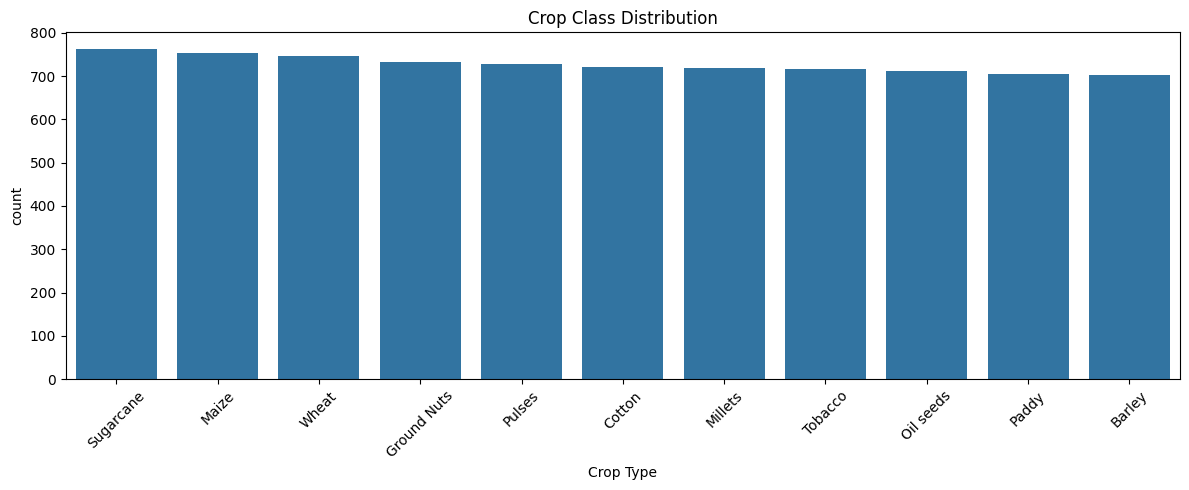

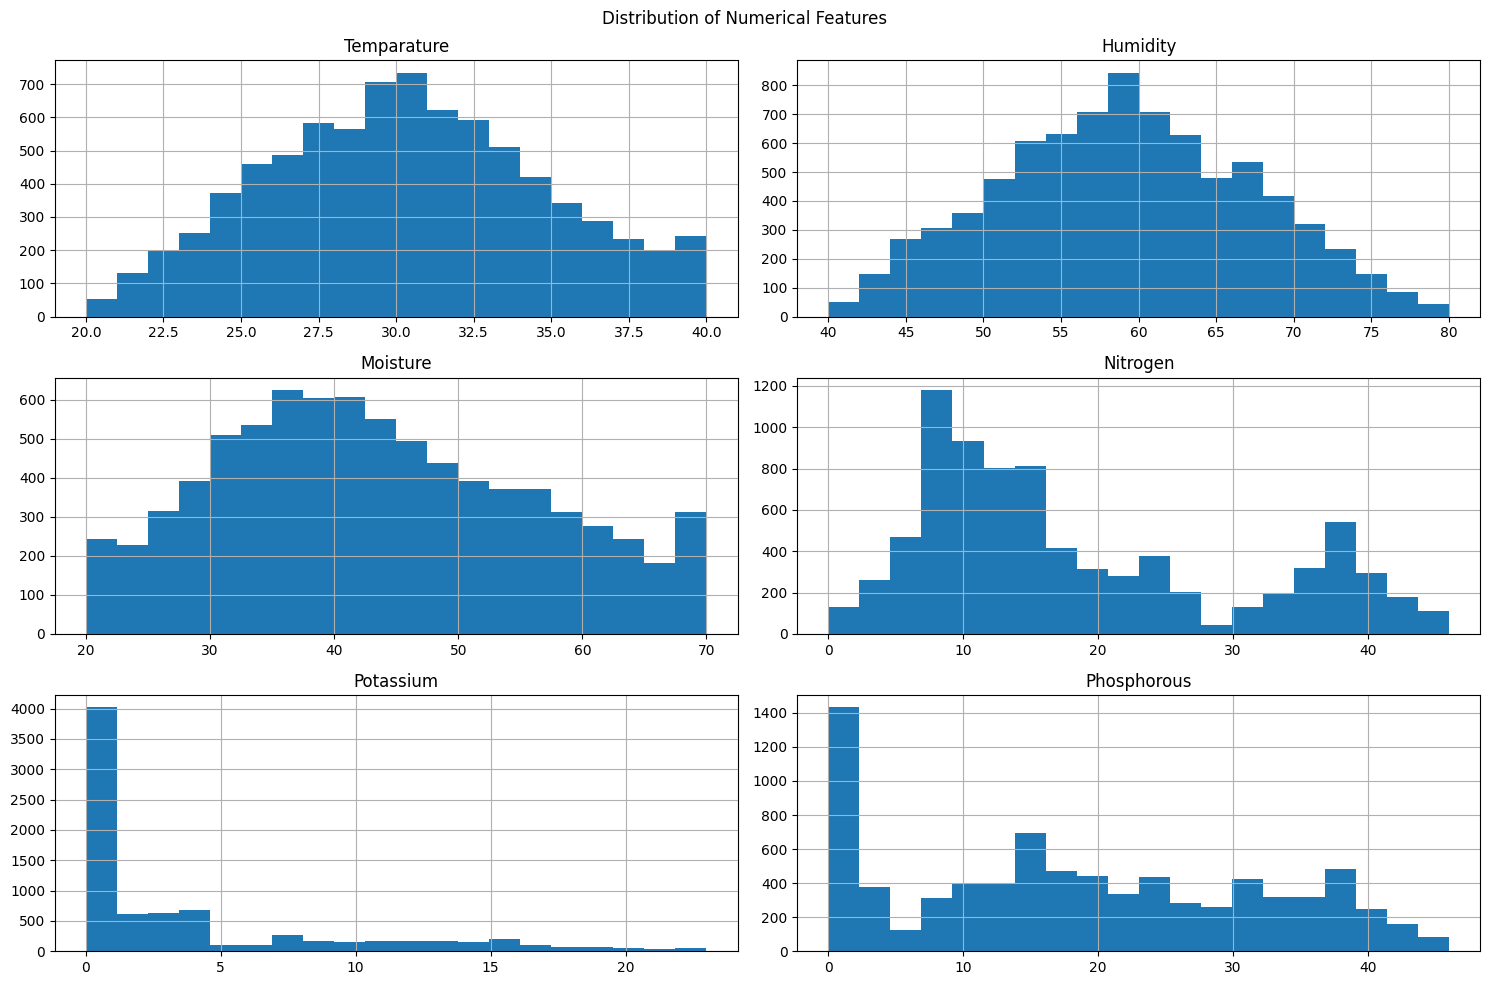

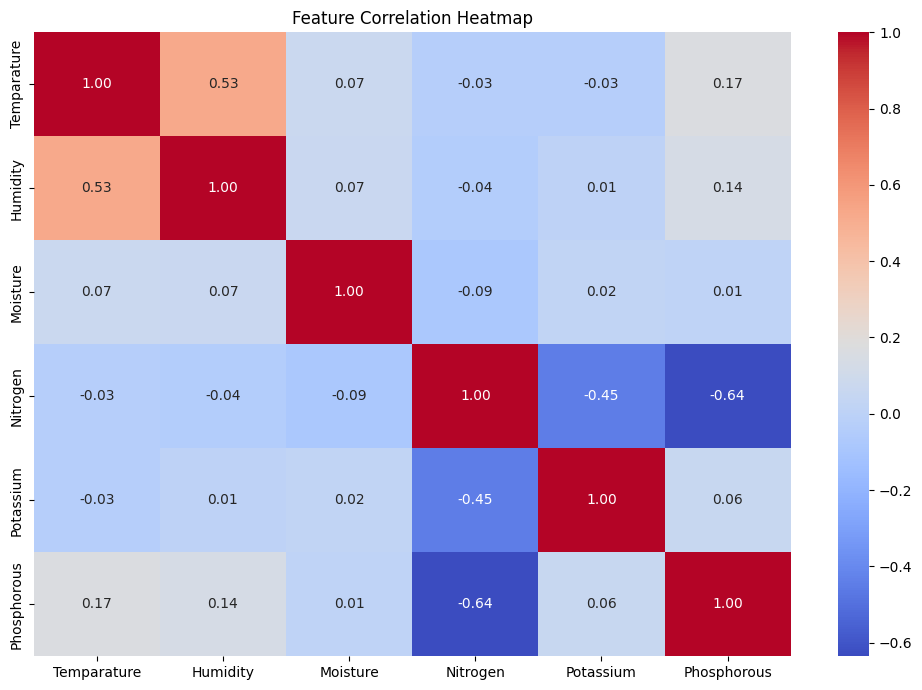

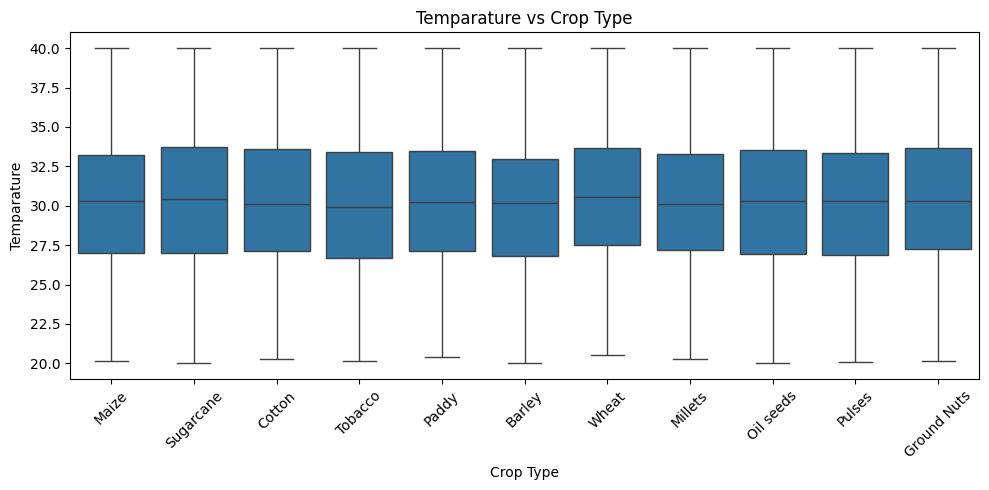

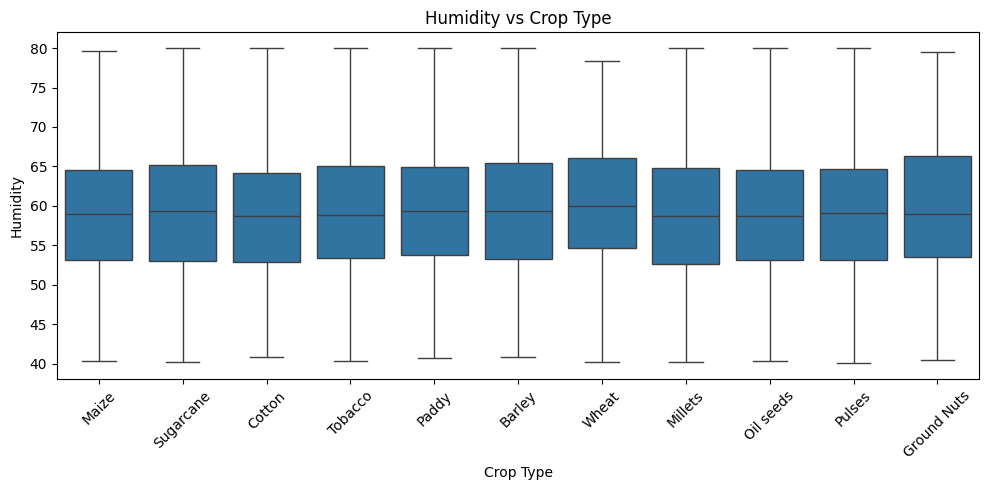

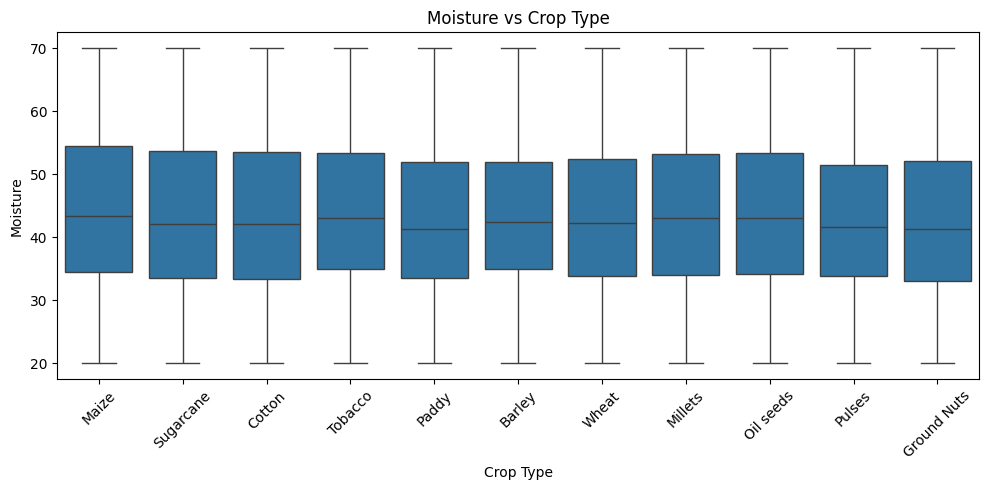

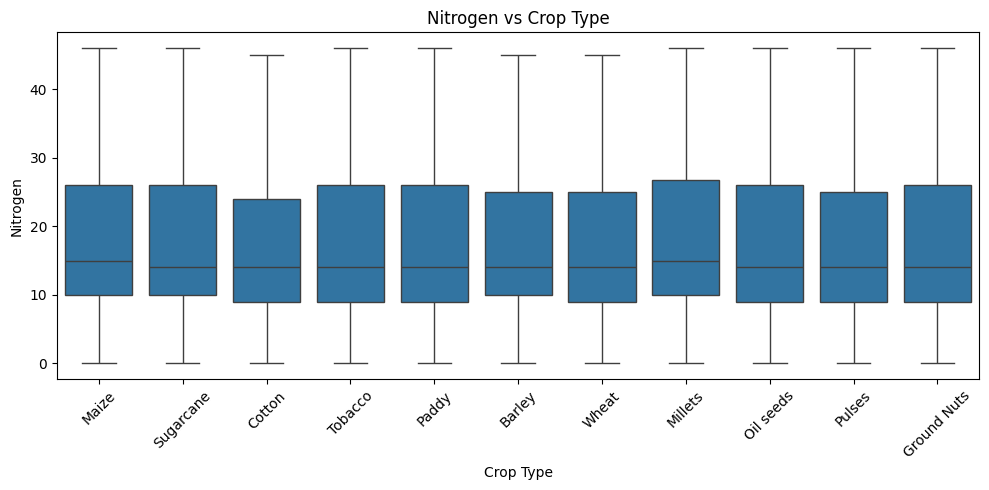

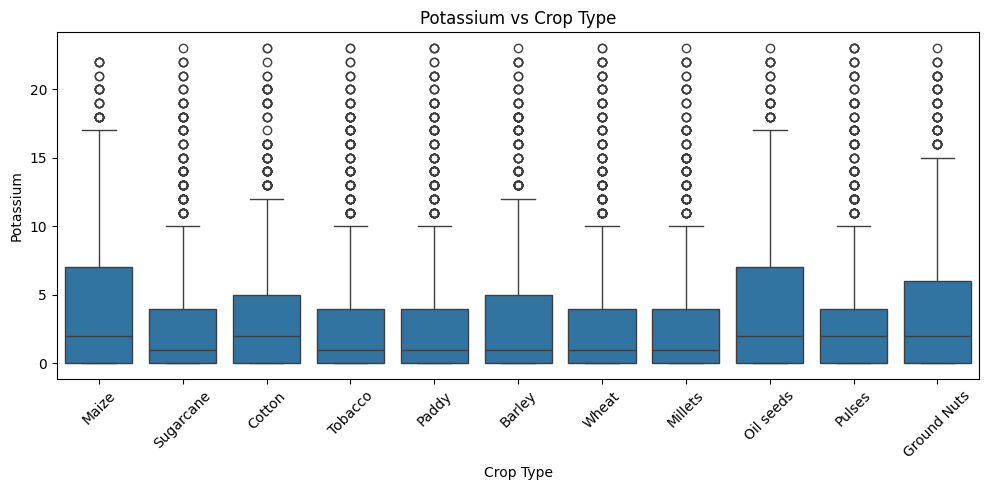

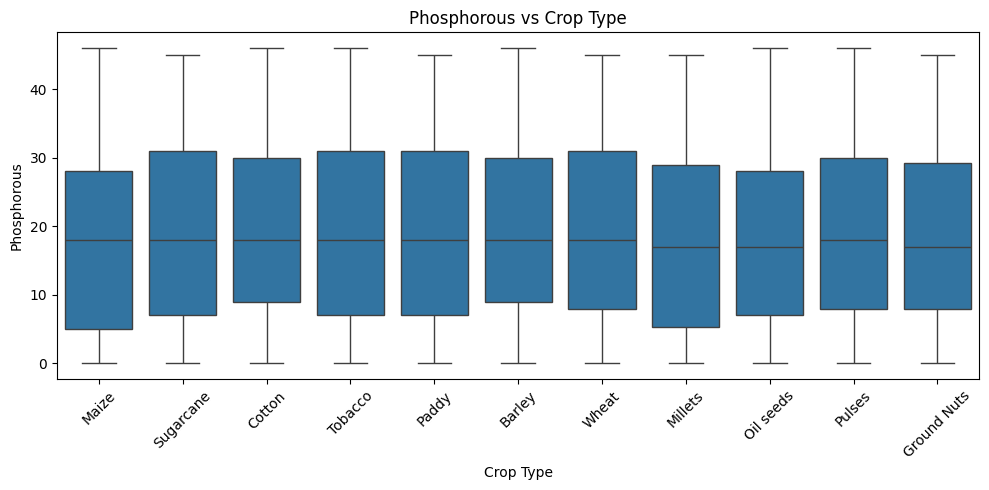

In [ ]:

# Target class distribution
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index)
plt.title("Crop Class Distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Numerical feature distribution
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numeric_cols].hist(figsize=(15, 10), bins=20)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

# Correlation heatmap
if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# Crop-wise distribution of numerical variables
if numeric_cols:
    for col in numeric_cols[:6]:
        plt.figure(figsize=(10, 5))
        sns.boxplot(data=df, x=TARGET, y=col)
        plt.title(f"{col} vs Crop Type")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()


In [ ]:

# Separate input and output
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(str)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Numerical features: ['Temparature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']
Categorical features: ['Soil Type', 'Fertilizer Name']
Training samples: 6400
Testing samples: 1600


In [ ]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Support Vector Machine": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = pipeline

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("F1 Score:", round(f1, 4))

print("\nAll models trained successfully!")



Training: Logistic Regression
Accuracy: 9.56 %
F1 Score: 0.0935

Training: K-Nearest Neighbors
Accuracy: 8.94 %
F1 Score: 0.0868

Training: Support Vector Machine
Accuracy: 9.75 %
F1 Score: 0.0961

Training: Random Forest
Accuracy: 9.62 %
F1 Score: 0.0965

Training: Extra Trees
Accuracy: 8.94 %
F1 Score: 0.0897

All models trained successfully!


,Model,Accuracy,Precision,Recall,F1 Score
0,Support Vector Machine,0.0975,0.0970,0.0975,0.0961
1,Random Forest,0.0963,0.0974,0.0963,0.0965
2,Logistic Regression,0.0956,0.0928,0.0956,0.0935
3,K-Nearest Neighbors,0.0894,0.0960,0.0894,0.0868
4,Extra Trees,0.0894,0.0906,0.0894,0.0897


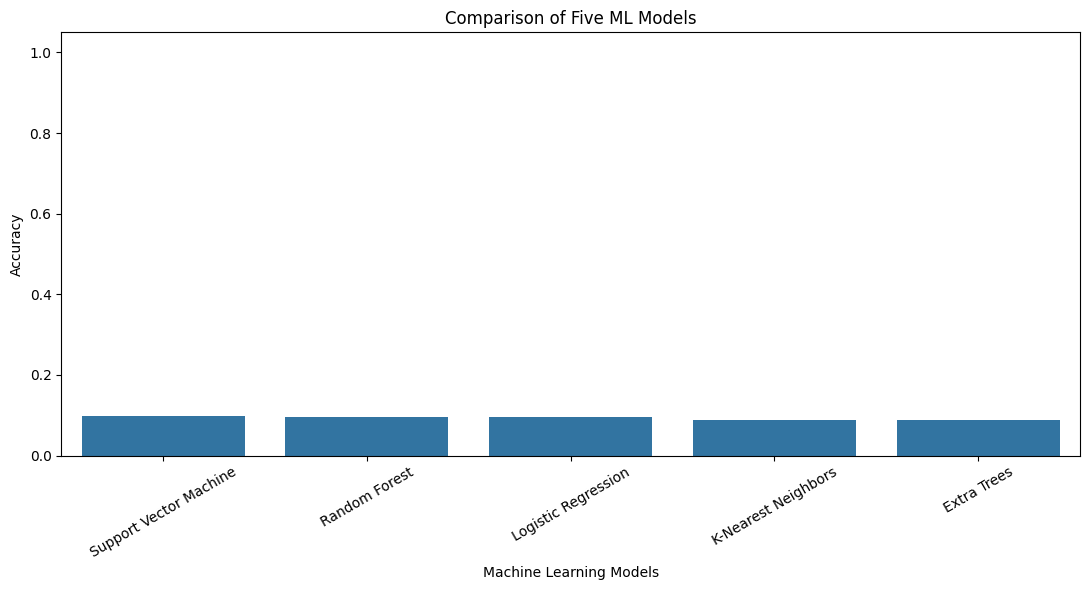

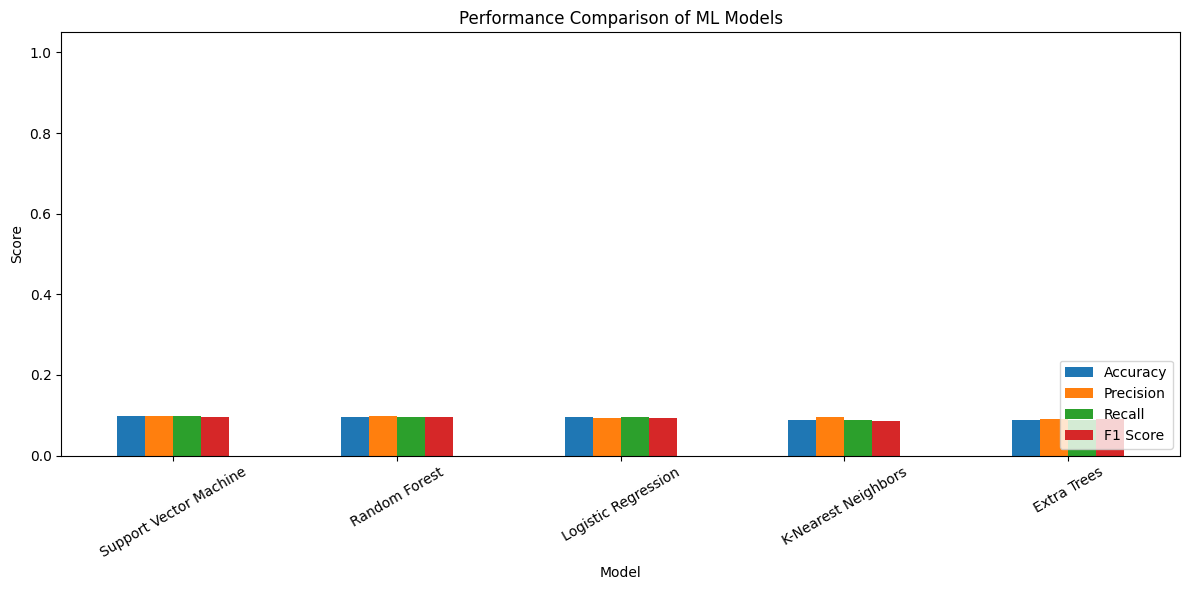

In [ ]:

# Create comparison dataframe
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    }).highlight_max(
        subset=["Accuracy", "Precision", "Recall", "F1 Score"],
        color="lightgreen"
    )
)

# Accuracy comparison graph
plt.figure(figsize=(11, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Five ML Models")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Compare all evaluation metrics
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Performance Comparison of ML Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [ ]:

# Select model with highest accuracy
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("BEST MODEL:", best_model_name)

print(
    "Best Accuracy:",
    round(results_df.iloc[0]["Accuracy"] * 100, 2),
    "%"
)

# Classification report
best_predictions = best_model.predict(X_test)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)


BEST MODEL: Support Vector Machine
Best Accuracy: 9.75 %

Classification Report:
              precision    recall  f1-score   support

      Barley       0.08      0.09      0.08       141
      Cotton       0.11      0.15      0.13       144
 Ground Nuts       0.11      0.12      0.12       146
       Maize       0.10      0.11      0.11       151
     Millets       0.11      0.11      0.11       144
   Oil seeds       0.12      0.10      0.11       142
       Paddy       0.06      0.06      0.06       141
      Pulses       0.11      0.10      0.10       146
   Sugarcane       0.09      0.06      0.07       153
     Tobacco       0.07      0.05      0.06       143
       Wheat       0.09      0.11      0.10       149

    accuracy                           0.10      1600
   macro avg       0.10      0.10      0.10      1600
weighted avg       0.10      0.10      0.10      1600



In [ ]:

if best_model_name in ["Random Forest", "Extra Trees"]:

    classifier = best_model.named_steps["classifier"]
    feature_names = best_model.named_steps[
        "preprocessor"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": classifier.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance", ascending=False
    ).head(15)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()
    plt.show()

    display(importance_df)
else:
    print("Feature importance plot is available for tree-based models.")


Feature importance plot is available for tree-based models.


In [ ]:

# Save complete pipeline including preprocessing
joblib.dump(best_model, "best_crop_prediction_model.pkl")

print("Best model saved successfully!")

# Download-ready Kaggle output location
print(os.path.abspath("best_crop_prediction_model.pkl"))


Best model saved successfully!
/kaggle/working/best_crop_prediction_model.pkl


In [ ]:

# Select one test record
sample = X_test.iloc[[0]]

prediction = best_model.predict(sample)

print("Input soil and environmental parameters:")
display(sample)

print("Recommended Crop:", prediction[0])

print("Actual Crop:", y_test.iloc[0])


Input soil and environmental parameters:


,Temparature,Humidity,Moisture,Soil Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
471,28.74,48.61,35.72,Red,14,3,37,14-35-14


Recommended Crop: Paddy
Actual Crop: Tobacco
